# XGBoost

In [1]:
IMPORT_MODEL = False
PARAMETERS_ADJUSTMENT = False
model_name = "13_xgb"

best_eta = 0.05
best_max_depth = 6
best_mcw = 35
best_num_boost_round = 403

In [2]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import warnings

import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split

from functional_files import _data, _evaluating, _featuring, _model_impex

warnings.filterwarnings('ignore')

pd.set_option('display.max_rows', None)      # all rows
pd.set_option('display.max_columns', None)   # all columns
pd.set_option('display.width', None)         # no line wrapping
pd.set_option('display.max_colwidth', None)  # don't truncate cell contents


## Data

In [3]:
df, _ = _data.get_data('1')

In [4]:
x = df.drop(columns='is_fraud')
y = df['is_fraud']
x_temp_raw, x_test_raw, y_temp, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=42)
x_train_raw, x_val_raw, y_train, y_val = train_test_split(x_temp_raw, y_temp, test_size=0.25, stratify=y_temp,
                                                          random_state=42)
x_train_raw = _featuring.simple(x_train_raw)
x_val_raw = _featuring.simple(x_val_raw)
x_test_raw = _featuring.simple(x_test_raw)

## Model

In [5]:
if IMPORT_MODEL:
    dv, _ = _model_impex.import_model(model_name)
    x_train = _model_impex.dv_transform(dv, x_train_raw)
    x_val = _model_impex.dv_transform(dv, x_val_raw)
    # x_test = _model_impex.dv_transform(dv, x_test_raw)
else:
    dv = _model_impex.dv_initializing(x_train_raw)
    x_train = _model_impex.dv_transform(dv, x_train_raw)
    x_val = _model_impex.dv_transform(dv, x_val_raw)
    # x_test = _model_impex.dv_transform(dv, x_test_raw)

In [6]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(x_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(x_val, label=y_val, feature_names=features)

### Parameters adjustment

In [7]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [8]:
if PARAMETERS_ADJUSTMENT:
    # Train XGBoost models for each eta and store AUC results
    scores = {} # dictionary to store results for each eta
    etas = [0.01, 0.05, 0.1, 0.3, 1.0] # list of parameter values. in this case it is 'eta'.

    for eta in etas:
        evals_result = {}

        xgb_params = {
            'eta': eta,
            'max_depth': 6,
            'min_child_weight': 1,

            'objective': 'binary:logistic',
            'eval_metric': 'auc',

            'nthread': 8,
            'seed': 42,
            'verbosity': 1
        }

        model = xgb.train(
            xgb_params,
            dtrain,
            evals=watchlist,
            verbose_eval=0,
            num_boost_round=1000,
            evals_result=evals_result
        )

        columns = ['iter', 'train_auc', 'val_auc']
        val_aucs = list(evals_result['val'].values())[0]

        key = f'{eta}'
        scores[key] = max(val_aucs)

        print("eta:", eta)

In [9]:
if PARAMETERS_ADJUSTMENT:
    df_scores = pd.DataFrame.from_dict(scores, orient='index', columns=['auc'])
    df_scores = df_scores.sort_values(by='auc', ascending=False)
    best_eta = 0.05 #float(df_scores['auc'].idxmax())
    display(df_scores)

In [10]:
if PARAMETERS_ADJUSTMENT:
    # Train XGBoost models for each eta and store AUC results
    scores = {} # dictionary to store results for each eta
    max_depths = np.arange(1, 10, 1) # list of parameter values. in this case it is 'eta'.

    for depth in max_depths:
        evals_result = {}

        xgb_params = {
            'eta': best_eta,
            'max_depth': depth,
            'min_child_weight': 1,

            'objective': 'binary:logistic',
            'eval_metric': 'auc',

            'nthread': 8,
            'seed': 42,
            'verbosity': 1
        }

        model = xgb.train(
            xgb_params,
            dtrain,
            evals=watchlist,
            verbose_eval=0,
            num_boost_round=1000,
            evals_result=evals_result
        )

        columns = ['iter', 'train_auc', 'val_auc']
        val_aucs = list(evals_result['val'].values())[0]

        key = f'{depth}'
        scores[key] = max(val_aucs)

        print("Depth:", depth)

In [11]:
if PARAMETERS_ADJUSTMENT:
    df_scores = pd.DataFrame.from_dict(scores, orient='index', columns=['auc'])
    df_scores = df_scores.sort_values(by='auc', ascending=False)
    best_max_depth = 10 # int(df_scores['auc'].idxmax())
    display(df_scores)

In [12]:
if PARAMETERS_ADJUSTMENT:
    # Train XGBoost models for each eta and store AUC results
    scores = {} # dictionary to store results for each eta
    options = np.arange(1, 100, 5) # list of parameter values. in this case it is 'eta'.

    for mcw in options:
        evals_result = {}

        xgb_params = {
            'eta': best_eta,
            'max_depth': best_max_depth,
            'min_child_weight': mcw,

            'objective': 'binary:logistic',
            'eval_metric': 'auc',

            'nthread': 8,
            'seed': 42,
            'verbosity': 1
        }

        model = xgb.train(
            xgb_params,
            dtrain,
            evals=watchlist,
            verbose_eval=0,
            num_boost_round=1000,
            evals_result=evals_result
        )

        columns = ['iter', 'train_auc', 'val_auc']
        val_aucs = list(evals_result['val'].values())[0]

        key = f'{mcw}'
        scores[key] = max(val_aucs)

        print("MCW:", mcw)

In [13]:
if PARAMETERS_ADJUSTMENT:
    df_scores = pd.DataFrame.from_dict(scores, orient='index', columns=['auc'])
    df_scores = df_scores.sort_values(by='auc', ascending=False)
    best_mcw = int(df_scores['auc'].idxmax()) - 1
    display(df_scores.head())

In [14]:
if PARAMETERS_ADJUSTMENT:
    evals_result = {}

    xgb_params = {
        'eta': best_eta,
        'max_depth': best_max_depth,
        'min_child_weight': best_mcw,

        'objective': 'binary:logistic',
        'eval_metric': 'auc',

        'nthread': 8,
        'seed': 42,
        'verbosity': 1
    }

    model = xgb.train(
        xgb_params,
        dtrain,
        evals=watchlist,
        verbose_eval=0,
        num_boost_round=1000,
        evals_result=evals_result
    )

In [15]:
if PARAMETERS_ADJUSTMENT:
    df_scores = pd.DataFrame(evals_result['val']['auc'], columns=['auc'])
    df_scores = df_scores.sort_values(by='auc', ascending=False)
    best_num_boost_round = int(df_scores['auc'].idxmax()) - 1
    display(df_scores.head())

In [16]:
if IMPORT_MODEL:
    _, model = _mode_impex.import_model(model_name)
else:
    xgb_params = {
        'eta': best_eta,
        'max_depth': best_max_depth,
        'min_child_weight': best_mcw,

        'objective': 'binary:logistic',
        'nthread': 8,

        'seed': 42,
        'verbosity': 1,
    }
    model = xgb.train(xgb_params, dtrain, num_boost_round=best_num_boost_round)
    _model_impex.export_model(model_name, dv, model)

ROC AUC: 0.9438775829799918
PR AUC: 0.49423406894008043


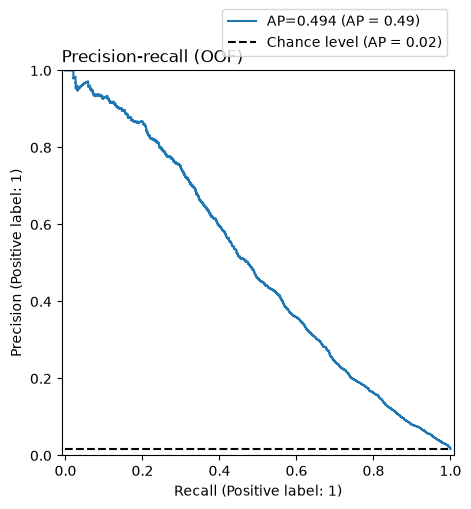

In [17]:
prediction = model.predict(dval)
_evaluating.full_score(y_val, prediction)
_evaluating.plot_pr_auc(y_val, prediction)

#### Conclusion 6
XGBoost model shows itself to be slightly more successful in respect to AUC score.

Some of the best values of parameters were chosen manually rather automatically to insure the balance, but not overfitting with local best parameters.

In [18]:
_, df_test_raw = _data.get_data('1')
df_test = _model_impex.dv_transform(dv, df_test_raw)
dtest = xgb.DMatrix(df_test, feature_names=features)
predicted = model.predict(dtest)
_data.kaggle_solution_import(predicted, '13')